# XAI – 01 Explaining Model 2 (MobileNetV3, then DeiT)
**Purpose:** Show WHERE the model looks when it predicts a body region, with 3 methods:
Grad-CAM, Grad-CAM++ (gradient-weighted feature maps) and Integrated Gradients (pixel attribution).
Then check known risks: chest resolution shortcut, drawn annotations, and errors.
**Inputs:** outputs/model2/ (manifest_split.csv, cache_224.npz, mobilenetv3_model2_best.pt, preds_*_test.csv)
**Outputs:** outputs/xai/ (figures for the report/slides)

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
M2_DIR  = DRIVE_ROOT / 'outputs' / 'model2'
XAI_DIR = DRIVE_ROOT / 'outputs' / 'xai'

SEED, IMG_SIZE = 42, 224
IG_STEPS = 64          # Integrated Gradients: number of steps from black image to real image

In [2]:
!pip install -q grad-cam captum
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as T
XAI_DIR.mkdir(parents=True, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

df = pd.read_csv(M2_DIR / 'manifest_split.csv')
X = np.load(M2_DIR / 'cache_224.npz', allow_pickle=True)['images']
pred = pd.read_csv(M2_DIR / 'preds_mobilenetv3_test.csv')
print('Device:', device, '| cache', X.shape, '| test predictions', pred.shape)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 41.1 MB/s eta 0:00:00
Mounted at /content/drive
Device: cuda | cache (3712, 224, 224) | test predictions (519, 18)


In [3]:
import torch.nn as nn
from torchvision.models import mobilenet_v3_large

ck = torch.load(M2_DIR / 'mobilenetv3_model2_best.pt', map_location=device)
CLASSES, SUPER = ck['classes'], ck['super']
SHORT = {c: c.split(' - ')[0] for c in CLASSES}
MEAN, STD = ck['mean'], ck['std']

mb = mobilenet_v3_large()
mb.classifier[3] = nn.Linear(mb.classifier[3].in_features, len(CLASSES))
mb.load_state_dict(ck['state_dict']); mb.eval().to(device)

eval_tf = T.Compose([T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(MEAN, STD)])
def to_input(ci):  return eval_tf(Image.fromarray(X[ci])).unsqueeze(0).to(device)       # model input
def rgb01(ci):     return np.repeat(X[ci][..., None] / 255.0, 3, axis=2).astype(np.float32)  # for display

# sanity check: same probabilities as notebook 02?
P_COLS = [f'p_{SHORT[c]}' for c in CLASSES]
with torch.no_grad():
    p = torch.softmax(mb(torch.cat([to_input(ci) for ci in pred.cache_idx[:8]])), 1).cpu().numpy()
print('Max difference vs saved predictions:', np.abs(p - pred[P_COLS].values[:8]).max().round(4))

Max difference vs saved predictions: 0.0522


In [4]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from captum.attr import IntegratedGradients
from scipy.ndimage import gaussian_filter

TARGET_LAYERS = [mb.features[-1]]                      # last convolutional block (7x7 feature maps)
BLACK = T.Normalize(MEAN, STD)(torch.zeros(3, IMG_SIZE, IMG_SIZE)).unsqueeze(0).to(device)
ig = IntegratedGradients(mb)

def explain(ci, target):
    """Return 3 heatmaps (224x224, values 0-1) explaining class `target` for cached image `ci`."""
    x, maps = to_input(ci), {}
    for name, Method in [('Grad-CAM', GradCAM), ('Grad-CAM++', GradCAMPlusPlus)]:
        with Method(model=mb, target_layers=TARGET_LAYERS) as cam:
            maps[name] = cam(input_tensor=x, targets=[ClassifierOutputTarget(target)])[0]
    a = ig.attribute(x, baselines=BLACK, target=target, n_steps=IG_STEPS, internal_batch_size=16)
    a = gaussian_filter(a.abs().sum(1)[0].detach().cpu().numpy(), sigma=2)   # light blur for readability
    maps['Integrated Gradients'] = np.clip(a / (np.percentile(a, 99) + 1e-8), 0, 1)
    return maps

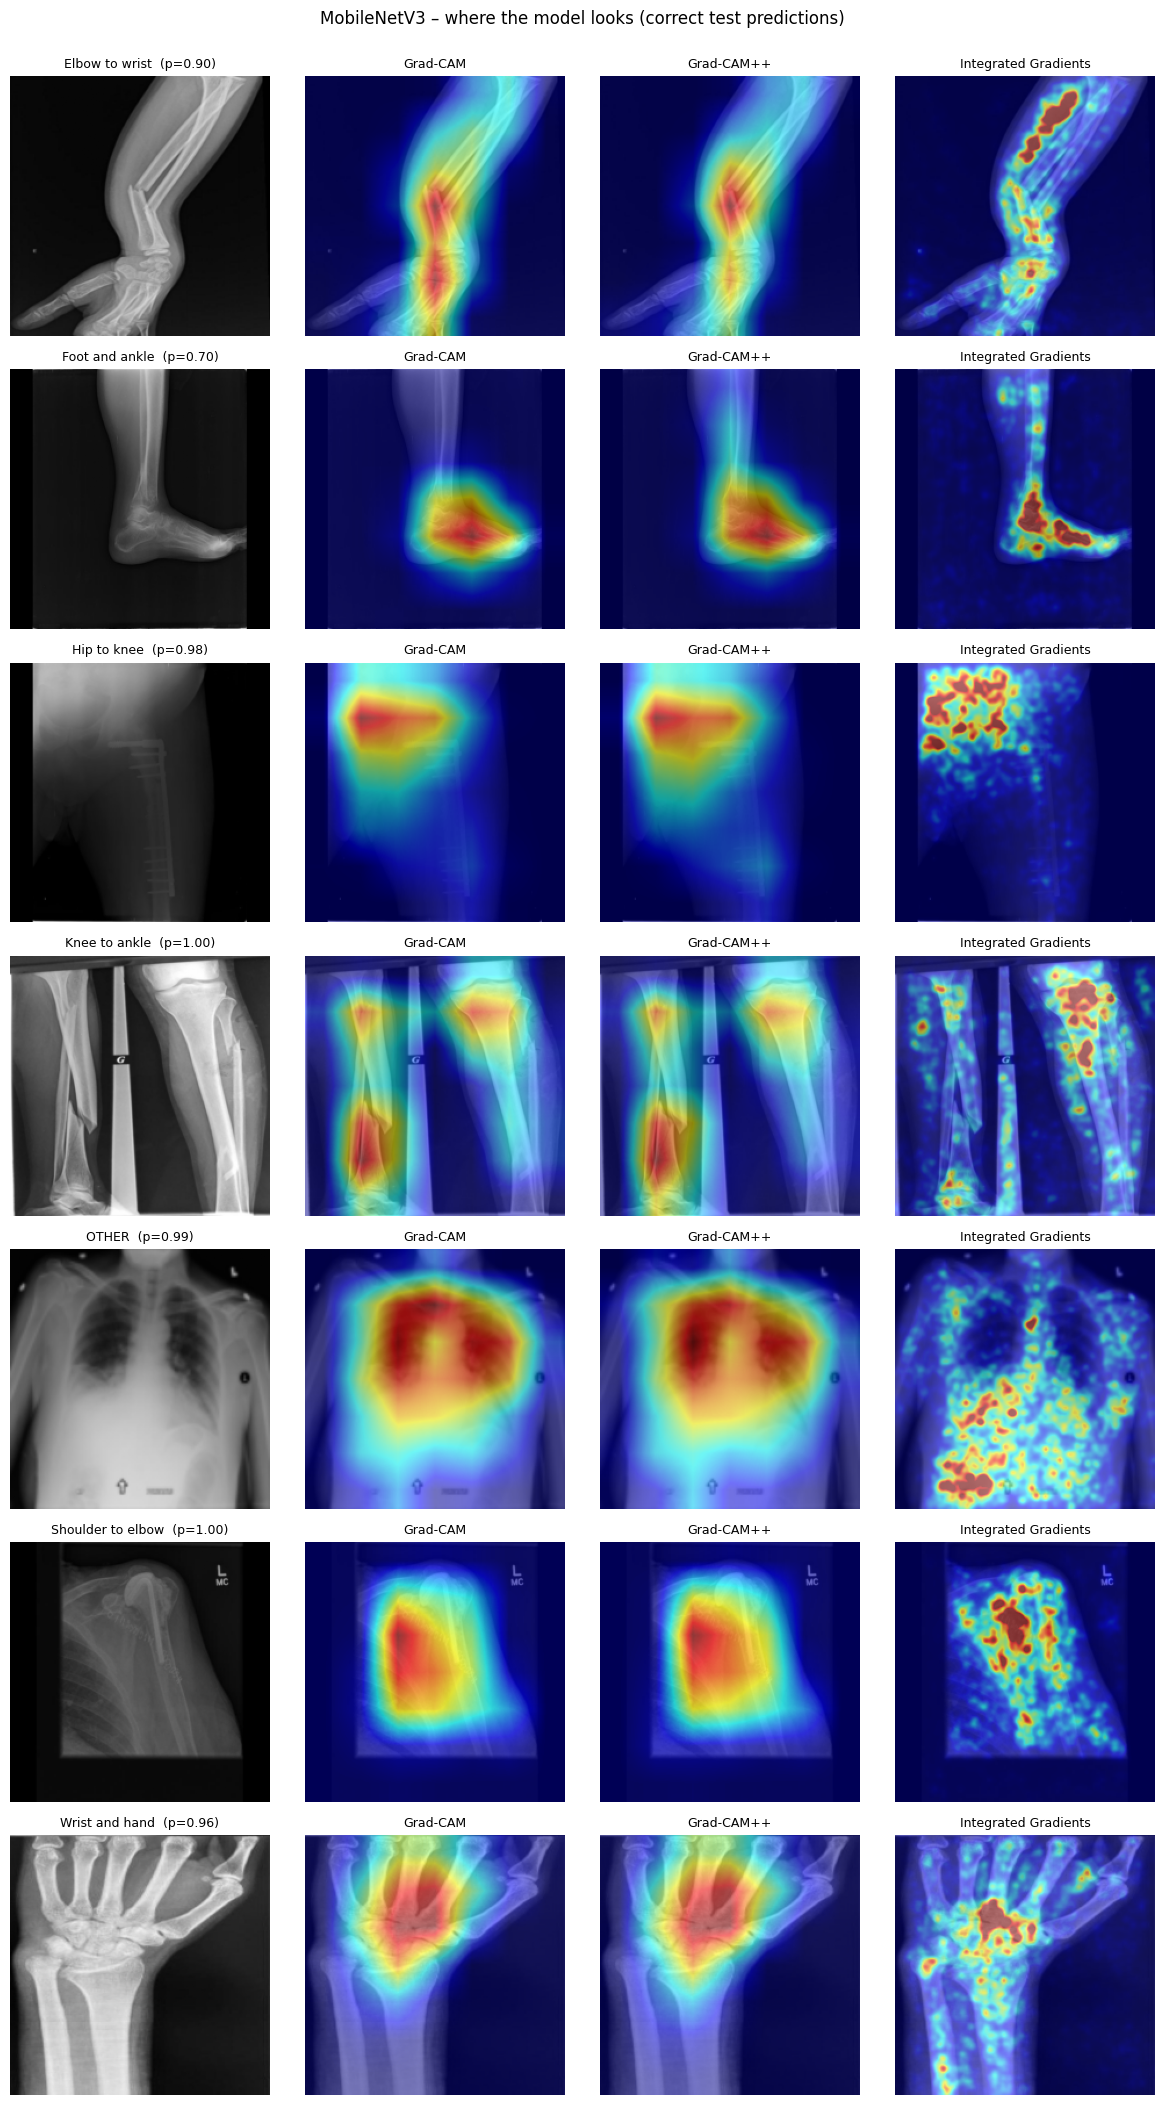

In [5]:
correct = pred[pred.label == pred.pred_label]
examples = correct.groupby('label').sample(1, random_state=SEED).set_index('label').loc[CLASSES].reset_index()

fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 3 * len(CLASSES)))
for row, (_, r) in zip(axes, examples.iterrows()):
    k = CLASSES.index(r.label)
    base, maps = rgb01(r.cache_idx), explain(r.cache_idx, k)
    row[0].imshow(base); row[0].set_title(f'{SHORT[r.label]}  (p={r[P_COLS[k]]:.2f})', fontsize=9)
    for ax, (m, h) in zip(row[1:], maps.items()):
        ax.imshow(show_cam_on_image(base, h, use_rgb=True)); ax.set_title(m, fontsize=9)
    for ax in row: ax.axis('off')
plt.suptitle('MobileNetV3 – where the model looks (correct test predictions)', y=1.0)
plt.tight_layout()
fig.savefig(XAI_DIR / 'mobilenetv3_3methods_per_class.png', dpi=120, bbox_inches='tight'); plt.show()

## Part B – Targeted checks
B0 Sanity check of the loaded model. B1 Resolution-shortcut test (make limb images 128 px like ChestMNIST – do they
become OTHER?). B2 Annotation check (how much Grad-CAM attention falls on coloured arrows/circles?).
B3 DeiT-Small Grad-CAM next to MobileNetV3 (do the two ensemble members look at the same anatomy?).

In [6]:
import timm

ckd = torch.load(M2_DIR / 'deit_small_model2_best.pt', map_location=device)
deit = timm.create_model(ckd['timm_name'], pretrained=False, num_classes=len(CLASSES))
deit.load_state_dict(ckd['state_dict']); deit.eval().to(device)
deit_tf = T.Compose([T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(ckd['mean'], ckd['std'])])
MODELS_X = {'MobileNetV3': (mb, eval_tf), 'DeiT-Small': (deit, deit_tf)}

@torch.no_grad()
def probs_of(model, tf, imgs):
    """Class probabilities for a list of PIL images."""
    out = []
    for i in range(0, len(imgs), 64):
        xb = torch.stack([tf(im) for im in imgs[i:i + 64]]).to(device)
        out.append(torch.softmax(model(xb).float(), 1).cpu())
    return torch.cat(out).numpy()

In [7]:
imgs = [Image.fromarray(X[ci]) for ci in pred.cache_idx]
saved = pred[P_COLS].values
p32 = probs_of(mb, eval_tf, imgs)
with torch.autocast('cuda'):
    p16 = probs_of(mb, eval_tf, imgs)
print('Same predicted class as notebook 02:', f'{(p32.argmax(1) == saved.argmax(1)).mean():.1%}')
print('Max prob. difference – full precision:', np.abs(p32 - saved).max().round(4),
      '| mixed precision (as in 02):', np.abs(p16 - saved).max().round(4))

Same predicted class as notebook 02: 98.3%
Max prob. difference – full precision: 0.1644 | mixed precision (as in 02): 0.0


In [8]:
def lowres(im, s):
    return im.resize((s, s), Image.BILINEAR).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

limb = pred[pred.label != 'OTHER']                               # 449 test images of arms and legs
y_limb = limb.label.map({c: i for i, c in enumerate(CLASSES)}).values
orig = [Image.fromarray(X[ci]) for ci in limb.cache_idx]
K_OTHER = CLASSES.index('OTHER')

for name, (m, tf) in MODELS_X.items():
    for s in [None, 128, 64]:
        p = probs_of(m, tf, orig if s is None else [lowres(im, s) for im in orig])
        tag = 'original' if s is None else f'{s}px'
        print(f'{name:12s} {tag:9s} | limb images predicted OTHER: {(p.argmax(1) == K_OTHER).mean():5.1%} '
              f'| mean P(OTHER): {p[:, K_OTHER].mean():.3f} | 7-class accuracy: {(p.argmax(1) == y_limb).mean():.1%}')

MobileNetV3  original  | limb images predicted OTHER:  0.2% | mean P(OTHER): 0.004 | 7-class accuracy: 91.1%
MobileNetV3  128px     | limb images predicted OTHER:  0.2% | mean P(OTHER): 0.004 | 7-class accuracy: 92.0%
MobileNetV3  64px      | limb images predicted OTHER:  0.2% | mean P(OTHER): 0.005 | 7-class accuracy: 89.5%
DeiT-Small   original  | limb images predicted OTHER:  0.0% | mean P(OTHER): 0.001 | 7-class accuracy: 93.1%
DeiT-Small   128px     | limb images predicted OTHER:  0.0% | mean P(OTHER): 0.002 | 7-class accuracy: 92.4%
DeiT-Small   64px      | limb images predicted OTHER:  0.0% | mean P(OTHER): 0.003 | 7-class accuracy: 91.1%


Annotated val+test images checked: 30
Coloured area (median): 0.5% of image | attention on it (median): 0.2%
Ratio attention/area – median 0.41 | images with ratio > 2: 1
(ratio 1 = no special attention; >1 = model looks MORE at the marks than chance)


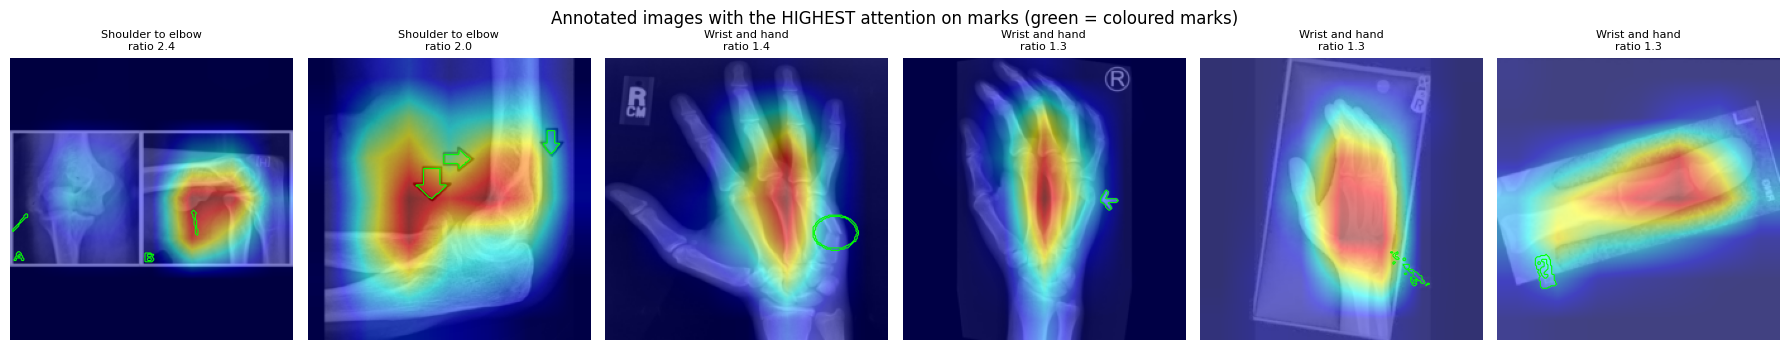

In [9]:
from PIL import ImageOps

def colour_mask_224(path):
    """Coloured pixels of the ORIGINAL image, mapped through the same pad-to-square + resize as the cache."""
    with Image.open(path) as im:
        a = np.asarray(ImageOps.exif_transpose(im).convert('RGB')).astype(np.int16)
    m = Image.fromarray(((a.max(2) - a.min(2)) > 40).astype(np.uint8) * 255)
    w, h = m.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0); canvas.paste(m, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 0

def gradcam_mb(ci, k):
    with GradCAM(model=mb, target_layers=TARGET_LAYERS) as cam:
        return cam(input_tensor=to_input(ci), targets=[ClassifierOutputTarget(k)])[0]

ann = df[df.has_colour_annotation & df.split.isin(['val', 'test'])]
rows = []
for _, r in ann.iterrows():
    m = colour_mask_224(r.path)
    if m.sum() == 0: continue
    h = gradcam_mb(r.cache_idx, CLASSES.index(r.label))
    share = h[m].sum() / (h.sum() + 1e-8)                  # share of attention on coloured pixels
    rows.append({'filename': r.filename, 'cache_idx': r.cache_idx, 'label': r.label, 'mask': m,
                 'area': m.mean(), 'attention_share': share, 'ratio': share / m.mean()})
res = pd.DataFrame(rows)
print('Annotated val+test images checked:', len(res))
print(f'Coloured area (median): {res.area.median():.1%} of image | attention on it (median): {res.attention_share.median():.1%}')
print(f'Ratio attention/area – median {res.ratio.median():.2f} | images with ratio > 2: {(res.ratio > 2).sum()}')
print('(ratio 1 = no special attention; >1 = model looks MORE at the marks than chance)')

top = res.sort_values('ratio', ascending=False).head(6)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, (_, r) in zip(axes, top.iterrows()):
    ax.imshow(show_cam_on_image(rgb01(r.cache_idx), gradcam_mb(r.cache_idx, CLASSES.index(r.label)), use_rgb=True))
    ax.contour(r['mask'], colors='lime', linewidths=0.8)
    ax.set_title(f'{SHORT[r.label]}\nratio {r.ratio:.1f}', fontsize=8); ax.axis('off')
plt.suptitle('Annotated images with the HIGHEST attention on marks (green = coloured marks)'); plt.tight_layout()
fig.savefig(XAI_DIR / 'annotation_check_top6.png', dpi=120, bbox_inches='tight'); plt.show()

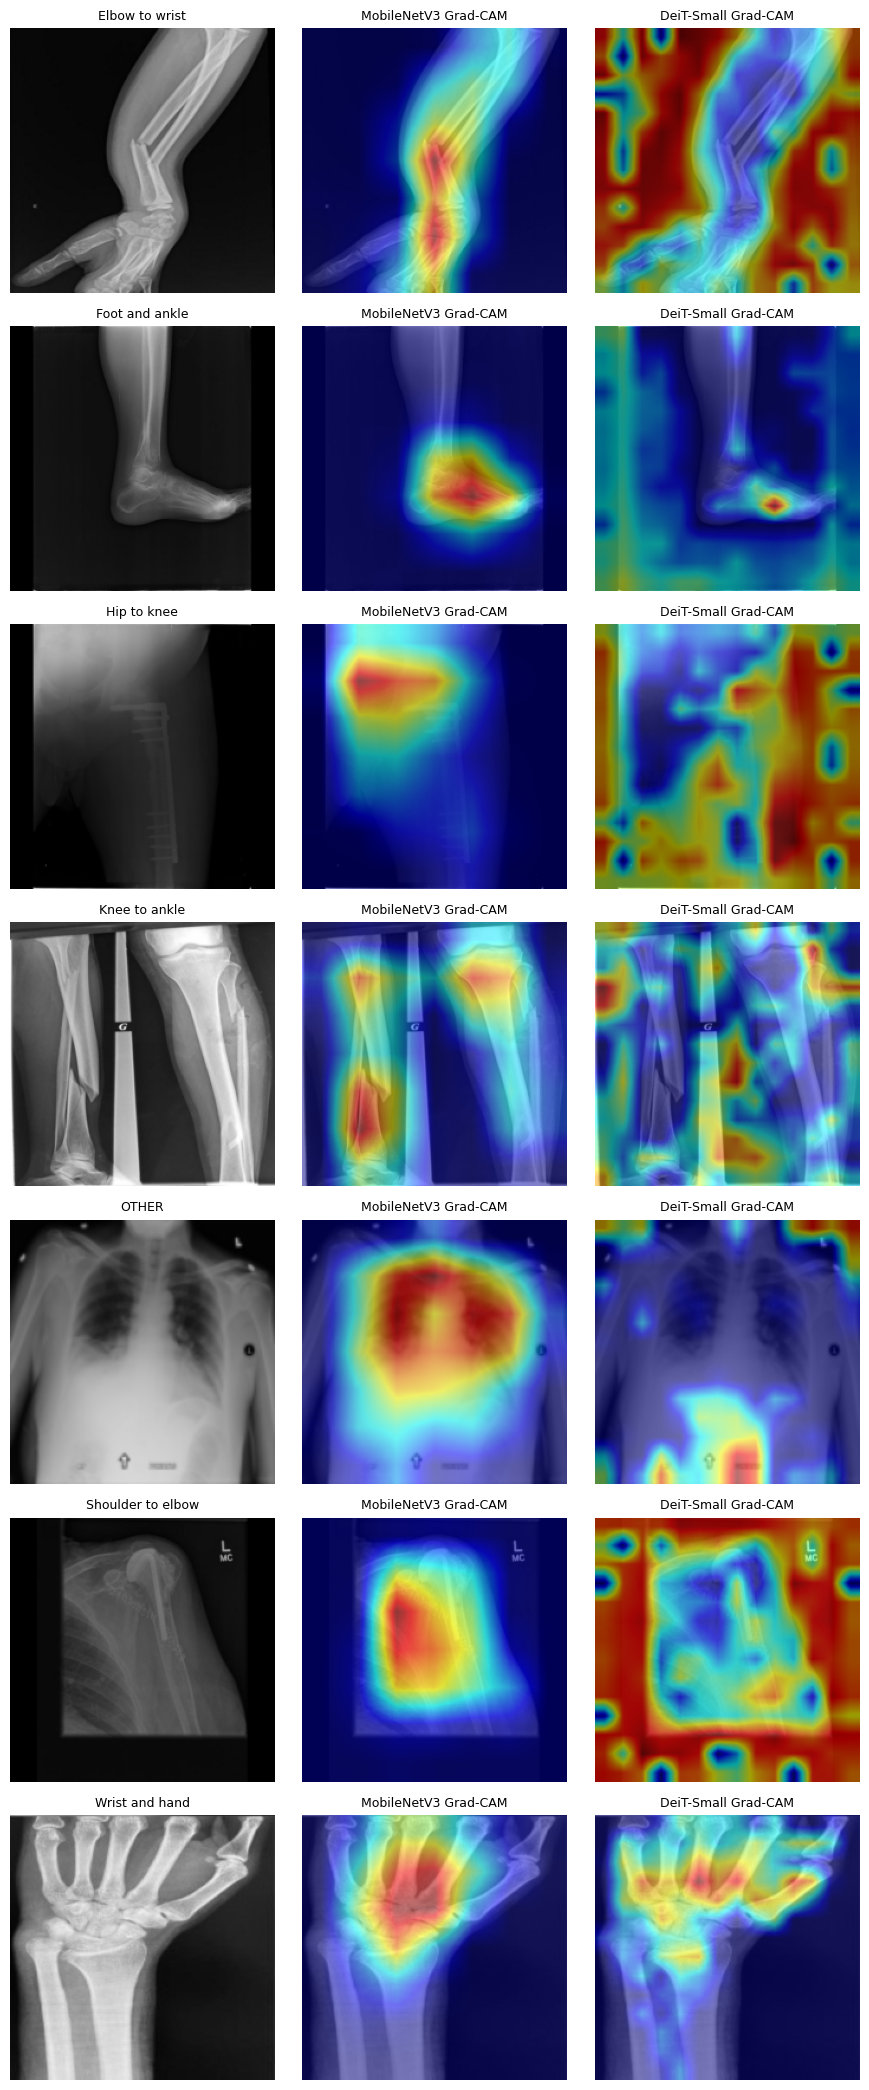

In [10]:
def vit_reshape(t):                                   # transformer tokens -> 14x14 "feature map"
    return t[:, 1:, :].reshape(t.size(0), 14, 14, t.size(2)).permute(0, 3, 1, 2)

def gradcam_deit(ci, k):
    x = deit_tf(Image.fromarray(X[ci])).unsqueeze(0).to(device)
    with GradCAM(model=deit, target_layers=[deit.blocks[-1].norm1], reshape_transform=vit_reshape) as cam:
        return cam(input_tensor=x, targets=[ClassifierOutputTarget(k)])[0]

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for row, (_, r) in zip(axes, examples.iterrows()):
    k, base = CLASSES.index(r.label), rgb01(r.cache_idx)
    row[0].imshow(base); row[0].set_title(SHORT[r.label], fontsize=9)
    row[1].imshow(show_cam_on_image(base, gradcam_mb(r.cache_idx, k), use_rgb=True)); row[1].set_title('MobileNetV3 Grad-CAM', fontsize=9)
    row[2].imshow(show_cam_on_image(base, gradcam_deit(r.cache_idx, k), use_rgb=True)); row[2].set_title('DeiT-Small Grad-CAM', fontsize=9)
    for ax in row: ax.axis('off')
plt.tight_layout()
fig.savefig(XAI_DIR / 'mobilenet_vs_deit_gradcam.png', dpi=120, bbox_inches='tight'); plt.show()

In [11]:
sample = pred.sample(100, random_state=SEED)
rows = []
for _, r in sample.iterrows():
    k = CLASSES.index(r.label)
    bg = X[r.cache_idx] < 15                                  # dark background / black padding pixels
    for name, fn in [('MobileNetV3', gradcam_mb), ('DeiT-Small', gradcam_deit)]:
        h = fn(r.cache_idx, k)
        rows.append({'model': name, 'bg_area': bg.mean(), 'bg_attention': h[bg].sum() / (h.sum() + 1e-8)})
bgres = pd.DataFrame(rows)
summary = bgres.groupby('model').agg(bg_area=('bg_area', 'median'), bg_attention=('bg_attention', 'median'))
summary['ratio'] = summary.bg_attention / summary.bg_area
print(summary.round(3))
print('\n(ratio < 1 = model looks LESS at background than its size; > 1 = MORE)')

             bg_area  bg_attention  ratio
model                                    
DeiT-Small     0.189         0.113  0.599
MobileNetV3    0.189         0.017  0.088

(ratio < 1 = model looks LESS at background than its size; > 1 = MORE)


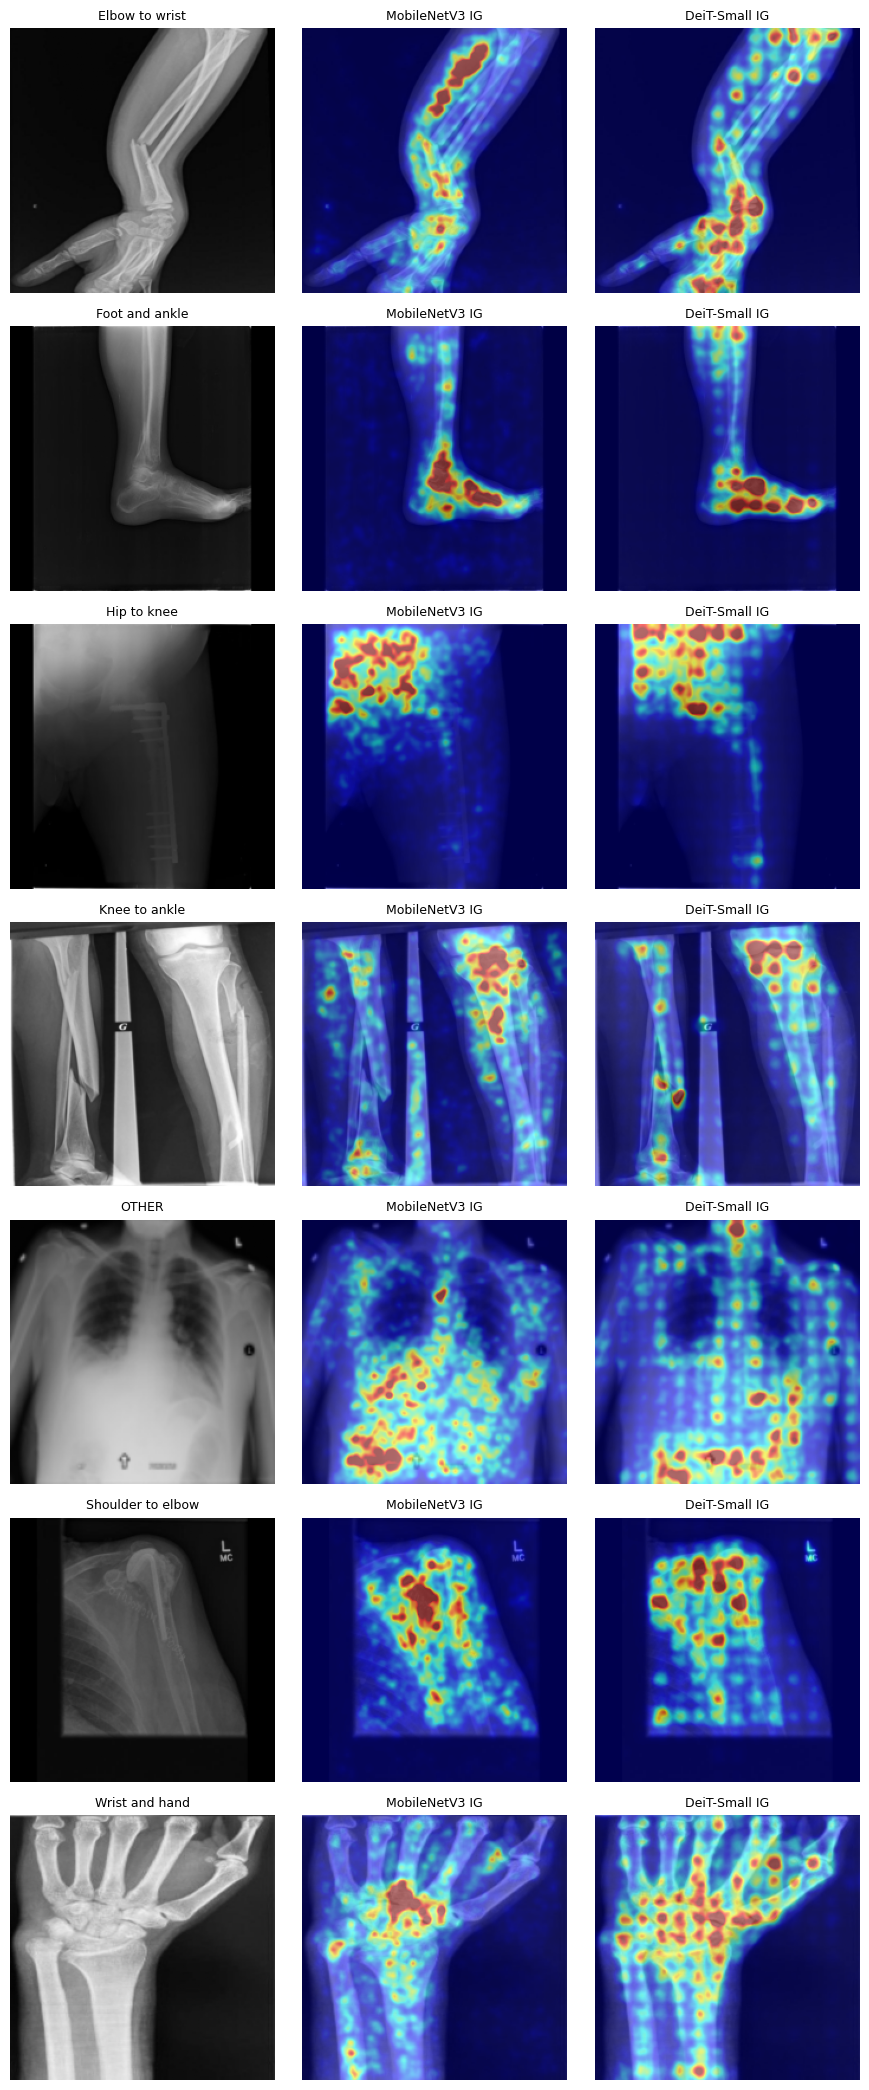

In [12]:
ig_deit = IntegratedGradients(deit)
BLACK_D = T.Normalize(ckd['mean'], ckd['std'])(torch.zeros(3, IMG_SIZE, IMG_SIZE)).unsqueeze(0).to(device)

def ig_map(igm, x, base, k):
    a = igm.attribute(x, baselines=base, target=k, n_steps=IG_STEPS, internal_batch_size=16)
    a = gaussian_filter(a.abs().sum(1)[0].detach().cpu().numpy(), sigma=2)
    return np.clip(a / (np.percentile(a, 99) + 1e-8), 0, 1)

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(9, 3 * len(CLASSES)))
for row, (_, r) in zip(axes, examples.iterrows()):
    k, base = CLASSES.index(r.label), rgb01(r.cache_idx)
    x_d = deit_tf(Image.fromarray(X[r.cache_idx])).unsqueeze(0).to(device)
    row[0].imshow(base); row[0].set_title(SHORT[r.label], fontsize=9)
    row[1].imshow(show_cam_on_image(base, ig_map(ig, to_input(r.cache_idx), BLACK, k), use_rgb=True)); row[1].set_title('MobileNetV3 IG', fontsize=9)
    row[2].imshow(show_cam_on_image(base, ig_map(ig_deit, x_d, BLACK_D, k), use_rgb=True)); row[2].set_title('DeiT-Small IG', fontsize=9)
    for ax in row: ax.axis('off')
plt.tight_layout()
fig.savefig(XAI_DIR / 'mobilenet_vs_deit_ig.png', dpi=120, bbox_inches='tight'); plt.show()

## Summary – XAI for Model 2
**3 methods (MobileNetV3):** Grad-CAM, Grad-CAM++ and Integrated Gradients agree; heat on the correct anatomy for all
7 classes (radius/ulna, ankle/tarsals, proximal femur, tibia/fibula, lungs/ribs, shoulder joint, carpals); markers
(R/L, "G", "L MC") and metal plates not highlighted.
**Resolution shortcut test:** limb test images degraded to 128 px / 64 px (ChestMNIST-like) → predicted OTHER 0.2% (MobileNetV3)
and 0.0% (DeiT) at every resolution; 7-class accuracy 91.1 → 89.5% at 64 px → no blur shortcut for chest (with the
resolution augmentation in place); robust to low-quality inputs.
**Annotation check (30 annotated val+test images):** coloured marks = 0.5% of image, 0.2% of Grad-CAM attention,
median ratio 0.41; 1/30 > 2, where arrows overlap the joint they point at. Limitation: only coloured marks detected.
**MobileNetV3 vs DeiT:** DeiT Grad-CAM noisier (background ratio 0.60 vs 0.09) but DeiT IG lies on the same anatomy
→ Grad-CAM less reliable on transformers. Decision: ensemble for prediction, MobileNetV3 Grad-CAM for user-facing explanation.
**Caveats:** IG uses a black baseline → cannot attribute pure-black regions; heatmaps show *where*, not *which feature*.
**Note:** model evaluated in mixed precision; full precision changes 1.7% of predicted classes → keep the same precision in deployment.
Figures saved in outputs/xai/.